In [2]:
pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 16.3 MB/s eta 0:00:00


Mounted at /content/drive
Extracting EDF parameters from /content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 183599  =      0.000 ...   367.198 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
<Info | 8 non-empty values
 bads: []
 ch_names: Trig, Fp1-LE, Fp2-LE, F3-LE, F4-LE, C3-LE, C4-LE, P3-LE, P4-LE, ...
 chs: 20 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2025-02-25 22:59:29 UTC
 nchan: 20
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: Azam>
>
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower t

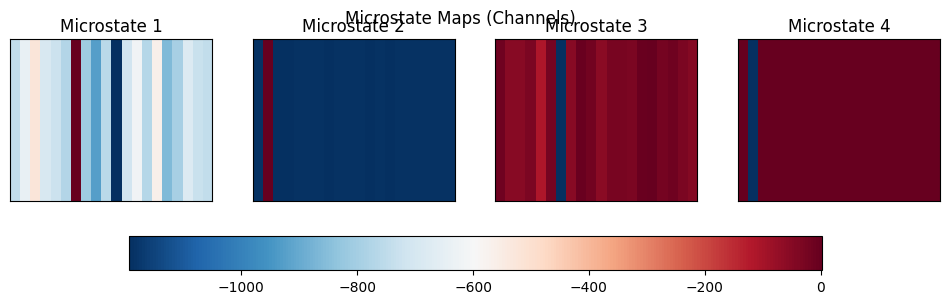

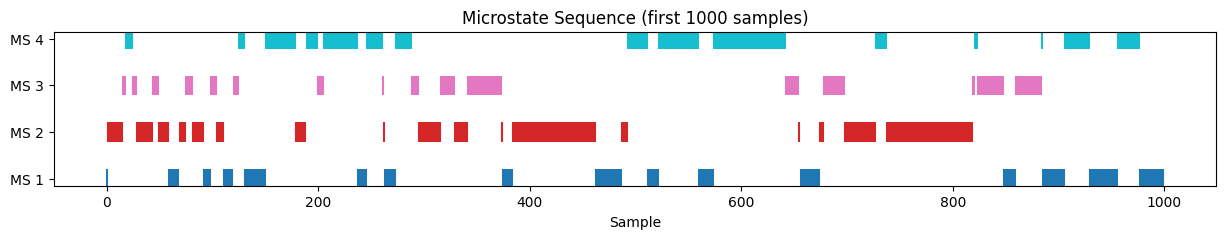

In [4]:
import numpy as np
import mne
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# -------------------------
# Step 1: Load EEG data (example with MNE sample data)
# -------------------------
from google.colab import drive
drive.mount('/content/drive')
edf_path = '/content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf'
raw = mne.io.read_raw_edf(edf_path, preload=True)
raw.pick_types(eeg=True)  # Only EEG channels

# View basic info
print(raw.info)
raw.filter(1., 40., fir_design='firwin')  # Band-pass filter

# -------------------------
# Step 2: Extract EEG data as numpy array (channels x time)
# -------------------------
data = raw.get_data()

# Transpose to (time x channels) for clustering
data = data.T

# -------------------------
# Step 3: Compute Global Field Power (GFP) to find peaks (microstate boundaries)
# -------------------------
gfp = np.std(data, axis=1)

# Find GFP peaks (local maxima) - simple approach
from scipy.signal import find_peaks
peaks, _ = find_peaks(gfp, distance=20)  # distance to avoid very close peaks

# Extract EEG topographies at GFP peaks
topographies = data[peaks]

# -------------------------
# Step 4: Clustering topographies to define microstates
# -------------------------
n_microstates = 4  # typically 4-6 microstates
kmeans = KMeans(n_clusters=n_microstates, random_state=42)
kmeans.fit(topographies)

# Microstate maps (cluster centers)
microstate_maps = kmeans.cluster_centers_

# -------------------------
# Step 5: Assign microstate labels to all time points (nearest cluster)
# -------------------------
from scipy.spatial.distance import cdist
distances = cdist(data, microstate_maps, metric='correlation')
labels = np.argmin(distances, axis=1)

# -------------------------
# Step 6: Visualize microstate maps
# -------------------------
fig, axes = plt.subplots(1, n_microstates, figsize=(12, 3))
for i in range(n_microstates):
    ax = axes[i]
    map = microstate_maps[i]
    im = ax.imshow(map.reshape(1, -1), aspect='auto', cmap='RdBu_r')
    ax.set_title(f'Microstate {i+1}')
    ax.set_yticks([])
    ax.set_xticks([])
plt.colorbar(im, ax=axes.ravel().tolist(), orientation='horizontal')
plt.suptitle('Microstate Maps (Channels)')
plt.show()

# -------------------------
# Step 7: Plot microstate sequence over time (example for 1000 samples)
# -------------------------
plt.figure(figsize=(15, 2))
plt.scatter(np.arange(1000), labels[:1000], c=labels[:1000], cmap='tab10', marker='|', s=200)
plt.yticks(range(n_microstates), [f'MS {i+1}' for i in range(n_microstates)])
plt.xlabel('Sample')
plt.title('Microstate Sequence (first 1000 samples)')
plt.show()


In [5]:
pip install mne-microstates

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting EDF parameters from /content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 183599  =      0.000 ...   367.198 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (3.302 s)

EE

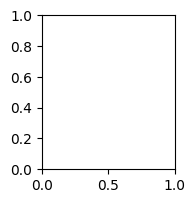

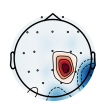

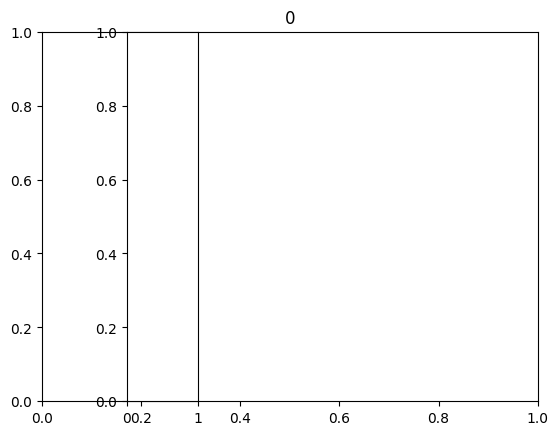

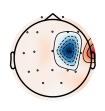

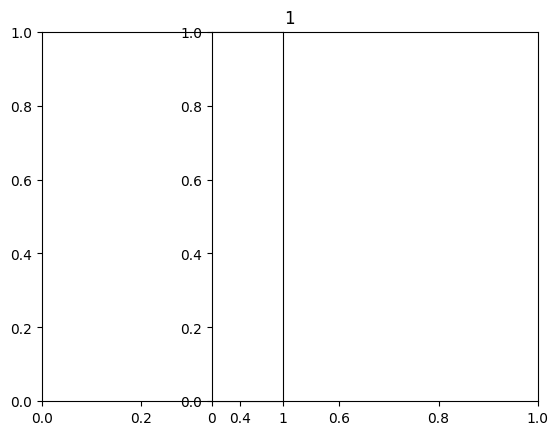

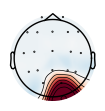

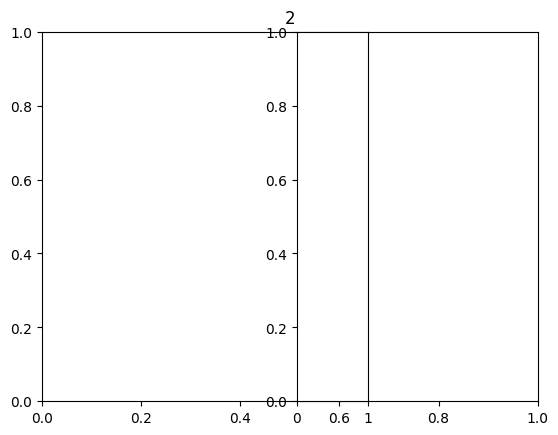

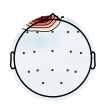

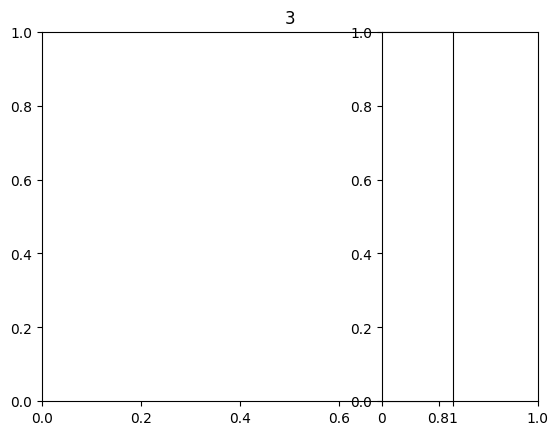

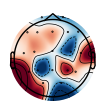

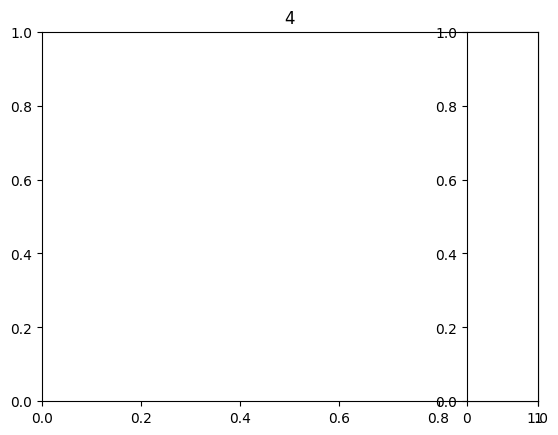

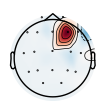

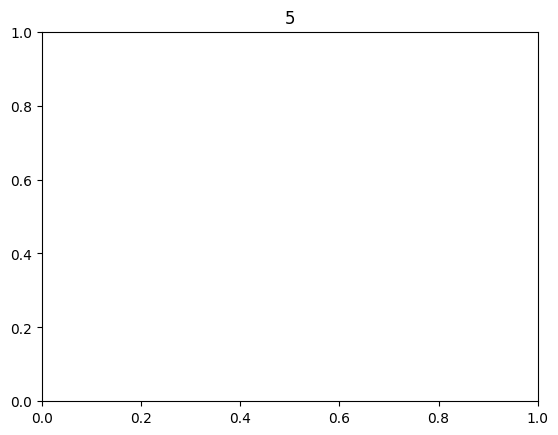

In [14]:
import mne
import mne_microstates
from google.colab import drive

drive.mount('/content/drive')
edf_path = '/content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf'
raw = mne.io.read_raw_edf(edf_path, preload=True)
raw.pick_types(eeg=True)  # Only EEG channels

# Rename channels to standard 10-20 names
rename_dict = {
    'Fp1-LE': 'Fp1',
    'Fp2-LE': 'Fp2',
    'F3-LE': 'F3',
    'F4-LE': 'F4',
    'C3-LE': 'C3',
    'C4-LE': 'C4',
    'P3-LE': 'P3',
    'P4-LE': 'P4',
    'O1-LE': 'O1',
    'O2-LE': 'O2',
    'F7-LE': 'F7',
    'F8-LE': 'F8',
    'T3-LE': 'T3',
    'T4-LE': 'T4',
    'T5-LE': 'T5',
    'T6-LE': 'T6',
    'Fz-LE': 'Fz',
    'Cz-LE': 'Cz',
    'Pz-LE': 'Pz',
}

raw.rename_channels(rename_dict)

# Drop non-EEG channels if present
if 'Trig' in raw.ch_names:
    raw.drop_channels(['Trig'])

raw.filter(1., 40., fir_design='firwin')
raw.set_eeg_reference('average')

# Add standard 10-20 montage
montage = mne.channels.make_standard_montage('standard_1020')
raw.set_montage(montage)

# Segment microstates
maps, segmentation = mne_microstates.segment(raw.get_data(), n_states=6)

# Plot microstate
mne_microstates.plot_maps(maps, raw.info)
# mne_microstates.plot_segmentation(segmentation[:500], raw.get_data()[:, :500], raw.times[:500])

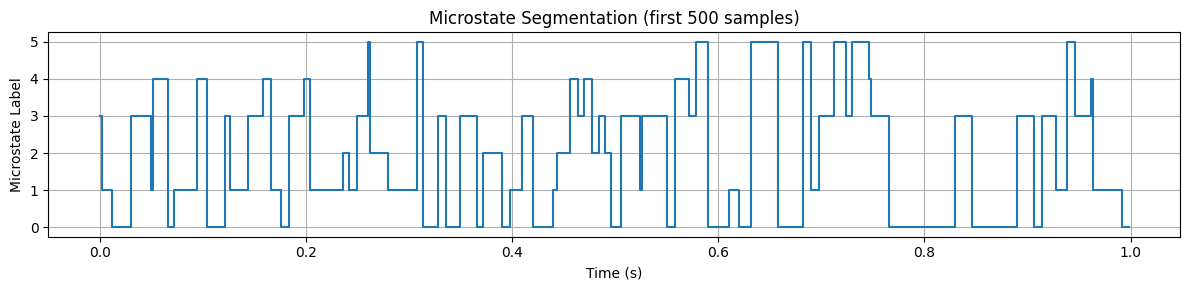

In [13]:
import matplotlib.pyplot as plt

# فرض: segmentation، raw.times قبلا محاسبه شده‌اند
plt.figure(figsize=(12, 3))

# رسم مرحله‌ای (step plot) برای نمایش تغییرات میکرواستیت‌ها
plt.step(raw.times[:500], segmentation[:500], where='post', color='tab:blue')

plt.xlabel('Time (s)')
plt.ylabel('Microstate Label')
plt.title('Microstate Segmentation (first 500 samples)')
plt.grid(True)
plt.tight_layout()
plt.show()
